# Generalized positive-P simulation of cat states, kittens and coherent-state mixtures in a photonic reservoir

This notebook accompanies the code in `generalized_pp.py`. It shows how superpositions and mixtures of coherent states are represented in the weighted (generalized) positive-P distribution, how their Wigner functions look, how they propagate through a coupled-waveguide chip, and how the output photon numbers $\langle \hat n_i\rangle$ and cross-correlations $g^{(2)}_{ij}$ are used for reservoir computing.

**Contents**
1. Theory: the weighted positive-P representation
2. States in the weighted positive-P distribution
3. Wigner functions
4. The photonic circuit
5. Propagation through the chip
6. Reservoir computing on the two-spirals task
7. Benchmark against exact Hilbert-space simulations (QuTiP)

**Running it yourself:** `pip install -r requirements.txt`, then open the notebook in Jupyter. The first call of the solver takes a few seconds because `numba` compiles it. Sections 6 and 7 take a few minutes in total.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from itertools import combinations
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from generalized_pp import (BlochToPP, coh_to_PP, PPToW, qutip_tester, Positive_P_CAT,
                            run_CAT, add_SuperGauss, J_matrix, master, Spirals)

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 10})
MODE_COLORS = ['#fe6100', '#785ef0', '#dc267f', '#648fff']

## 1. Theory: the weighted positive-P representation

Any state built from coherent states can be written as a **weighted sum of coherent-state pairs**

$$\hat\rho=\sum_k w_k\,\frac{|\alpha_k\rangle\langle\beta_k|}{\langle\beta_k|\alpha_k\rangle},\qquad \sum_k w_k = 1 .$$

* A **pure superposition** $|\psi\rangle\propto\sum_i c_i|\alpha_i\rangle$ gives $n^2$ pairs $(\alpha_i,\alpha_j)$ with weights $w_{ij}= \mathcal N\, c_i c_j^*\langle\alpha_j|\alpha_i\rangle$ (`coh_to_PP`).
* A state on the **Bloch sphere** spanned by $|\alpha\rangle,|-\alpha\rangle$ with Bloch vector $r(\sin\theta\cos\phi,\sin\theta\sin\phi,\cos\theta)$ gives 4 pairs (`BlochToPP`). $r=1$ is the pure cat $\cos\frac\theta2|\alpha\rangle+e^{i\phi}\sin\frac\theta2|-\alpha\rangle$, while $r=0$ is the classical mixture $\tfrac12(|\alpha\rangle\langle\alpha|+|-\alpha\rangle\langle-\alpha|)$.

The **diagonal** pairs ($\alpha_k=\beta_k$) are ordinary coherent states. The **off-diagonal** pairs carry the quantum coherence. Their weights contain $\langle-\alpha|\alpha\rangle=e^{-2|\alpha|^2}$, which is why small "kitten" states differ most from a mixture.

Every normally ordered moment is a weighted sum over the pairs,
$$\langle\hat a^{\dagger m}\hat a^n\rangle=\sum_k w_k\,\beta_k^{*m}\alpha_k^n ,$$
and each pair evolves as one phase-space trajectory $(\alpha,\tilde\alpha)$ with $\alpha^+=\tilde\alpha^*$. The circuit is linear, so the trajectories are deterministic, so the result is exact with a single trajectory per pair and **no Fock-space cutoff**.

The Wigner function of a pair is a complex Gaussian,
$$W_k(\gamma)=\frac{2}{\pi}\exp\!\big[-2(\gamma^*-\beta_k^*)(\gamma-\alpha_k)\big],\qquad W=\sum_k w_k W_k \quad(\texttt{PPToW}).$$

## 2. States in the weighted positive-P distribution

Each state is drawn in the complex plane. A dot is a diagonal pair $|\alpha\rangle\langle\alpha|$. An arrow from $\beta_k$ to $\alpha_k$ is an off-diagonal pair $|\alpha_k\rangle\langle\beta_k|$. Size and line width show $|w_k|$, and colour shows $\arg w_k$.

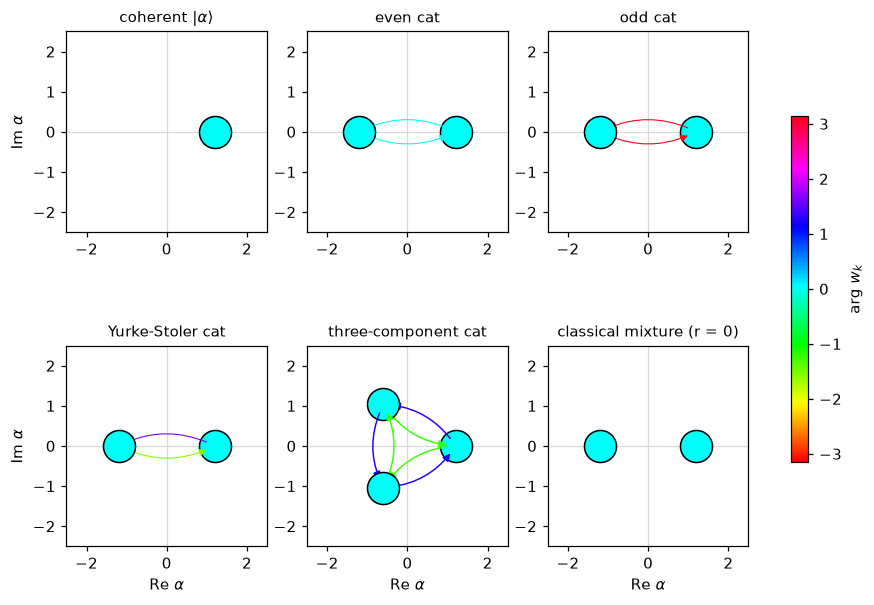

In [19]:
PHASE_CMAP, PHASE_NORM = plt.cm.hsv, mcolors.Normalize(-np.pi, np.pi)

def plot_pp(ax, PP, weights, title, lim=2.5):
    wmax = np.max(np.abs(weights))
    for (a, b), w in zip(PP, weights):
        if abs(w) < 1e-12:
            continue                      # pair absent from this state
        c = PHASE_CMAP(PHASE_NORM(np.angle(w)))
        if np.isclose(a, b):
            ax.scatter(a.real, a.imag, s=40 + 400*abs(w)/wmax, color=c, edgecolor='k', zorder=3)
        else:
            ax.annotate('', xy=(a.real, a.imag), xytext=(b.real, b.imag),
                        arrowprops=dict(arrowstyle='-|>', color=c, lw=0.5 + 4*abs(w)/wmax,
                                        connectionstyle='arc3,rad=0.25', shrinkA=6, shrinkB=6))
    ax.axhline(0, color='0.85', lw=0.8, zorder=0); ax.axvline(0, color='0.85', lw=0.8, zorder=0)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal', title=title,
           xlabel=r'Re $\alpha$', ylabel=r'Im $\alpha$')

alpha = 1.2
examples = {
    r'coherent $|\alpha\rangle$':  coh_to_PP([alpha], [1]),
    'even cat':                    coh_to_PP([alpha, -alpha], [1, 1]),
    'odd cat':                     coh_to_PP([alpha, -alpha], [1, -1]),
    'Yurke-Stoler cat':            coh_to_PP([alpha, -alpha], [1, 1j]),
    'three-component cat':         coh_to_PP(list(alpha*np.exp(2j*np.pi*np.arange(3)/3)), [1, 1, 1]),
    'classical mixture (r = 0)':   BlochToPP(0, np.pi/2, 0, alpha)[1:],
}
fig, axs = plt.subplots(2, 3, figsize=(10, 6.8))
for ax, (name, (PP, w)) in zip(axs.flat, examples.items()):
    plot_pp(ax, PP, w, name)
for ax in axs[:, 1:].flat: ax.set_ylabel('')
for ax in axs[0]: ax.set_xlabel('')
fig.colorbar(plt.cm.ScalarMappable(PHASE_NORM, PHASE_CMAP), ax=axs, shrink=0.6, label=r'arg $w_k$')
plt.show()

In [20]:
for name in ['even cat', 'classical mixture (r = 0)']:
    PP, w = examples[name]
    print(f'{name}  (alpha = {alpha})')
    print('   k      alpha_k        beta_k          w_k')
    for k, ((a, b), wk) in enumerate(zip(PP, w)):
        print(f'   {k}   {a:12.3f}  {b:12.3f}   {wk:16.4f}')
    print()

# the Bloch-sphere parametrisation reproduces the explicit superposition
PP_b, w_b = BlochToPP(1, np.pi/2, 0, alpha)[1:]
PP_c, w_c = coh_to_PP([alpha, -alpha], [1, 1])
print('BlochToPP(r=1, theta=pi/2, phi=0) vs coh_to_PP(even cat): max |dw| =', np.abs(w_b - w_c).max())

even cat  (alpha = 1.2)
   k      alpha_k        beta_k          w_k
   0   1.200+0.000j  1.200+0.000j     0.4734+0.0000j
   1   1.200+0.000j  -1.200+0.000j     0.0266+0.0000j
   2   -1.200+0.000j  1.200+0.000j     0.0266+0.0000j
   3   -1.200+0.000j  -1.200+0.000j     0.4734+0.0000j

classical mixture (r = 0)  (alpha = 1.2)
   k      alpha_k        beta_k          w_k
   0   1.200+0.000j  1.200+0.000j     0.5000+0.0000j
   1   1.200+0.000j  -1.200+0.000j     0.0000+0.0000j
   2   -1.200+0.000j  1.200+0.000j     0.0000+0.0000j
   3   -1.200+0.000j  -1.200+0.000j     0.5000+0.0000j

BlochToPP(r=1, theta=pi/2, phi=0) vs coh_to_PP(even cat): max |dw| = 5.551115123125783e-17


## 3. Wigner functions

### 3.1 Check against QuTiP
`PPToW` builds the Wigner function directly from the pairs, with no Fock space. `qutip_tester` computes it from the same state in a truncated Fock space.

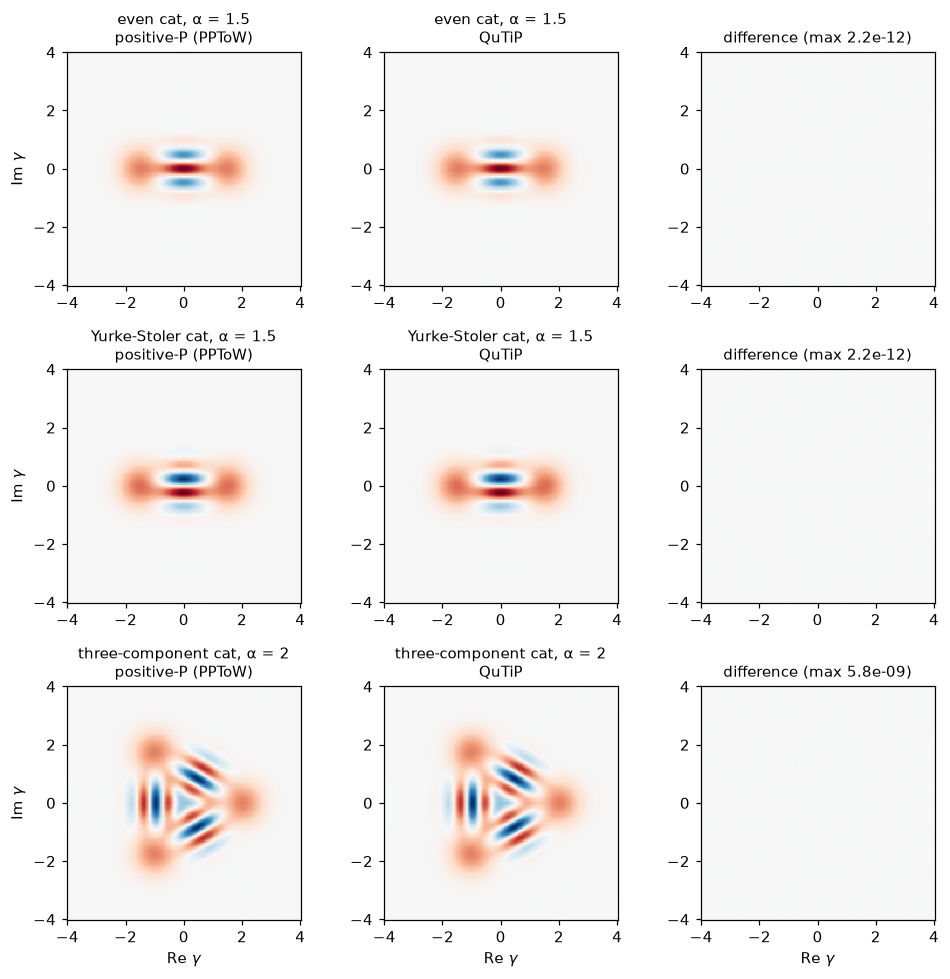

In [21]:
q = p = 4; Ns = 200
tests = {'even cat, α = 1.5': ([1.5, -1.5], [1, 1]),
         'Yurke-Stoler cat, α = 1.5': ([1.5, -1.5], [1, 1j]),
         'three-component cat, α = 2': (list(2*np.exp(2j*np.pi*np.arange(3)/3)), [1, 1, 1])}
fig, axs = plt.subplots(3, 3, figsize=(9, 9))
for row, (name, (st, cf)) in zip(axs, tests.items()):
    Q, P, W_pp = PPToW(*coh_to_PP(st, cf), q, p, Ns)
    _, _, W_qt = qutip_tester(st, cf, p, q, Ns)
    vm = np.abs(W_pp).max()
    for ax, Wplot, t in zip(row, [W_pp, W_qt, W_pp - W_qt], ['positive-P (PPToW)', 'QuTiP', 'difference']):
        im = ax.pcolormesh(Q, P, Wplot, cmap='RdBu_r', vmin=-vm, vmax=vm, rasterized=True)
        ax.set(aspect='equal', title=f'{name}\n{t}' if t != 'difference' else f'difference (max {np.abs(Wplot).max():.1e})')
    row[0].set_ylabel(r'Im $\gamma$')
for ax in axs[-1]: ax.set_xlabel(r'Re $\gamma$')
plt.tight_layout(); plt.show()

### 3.2 Across the Bloch sphere
Rows go from a pure cat ($r=1$) to the classical mixture ($r=0$). Columns are different points on the sphere.

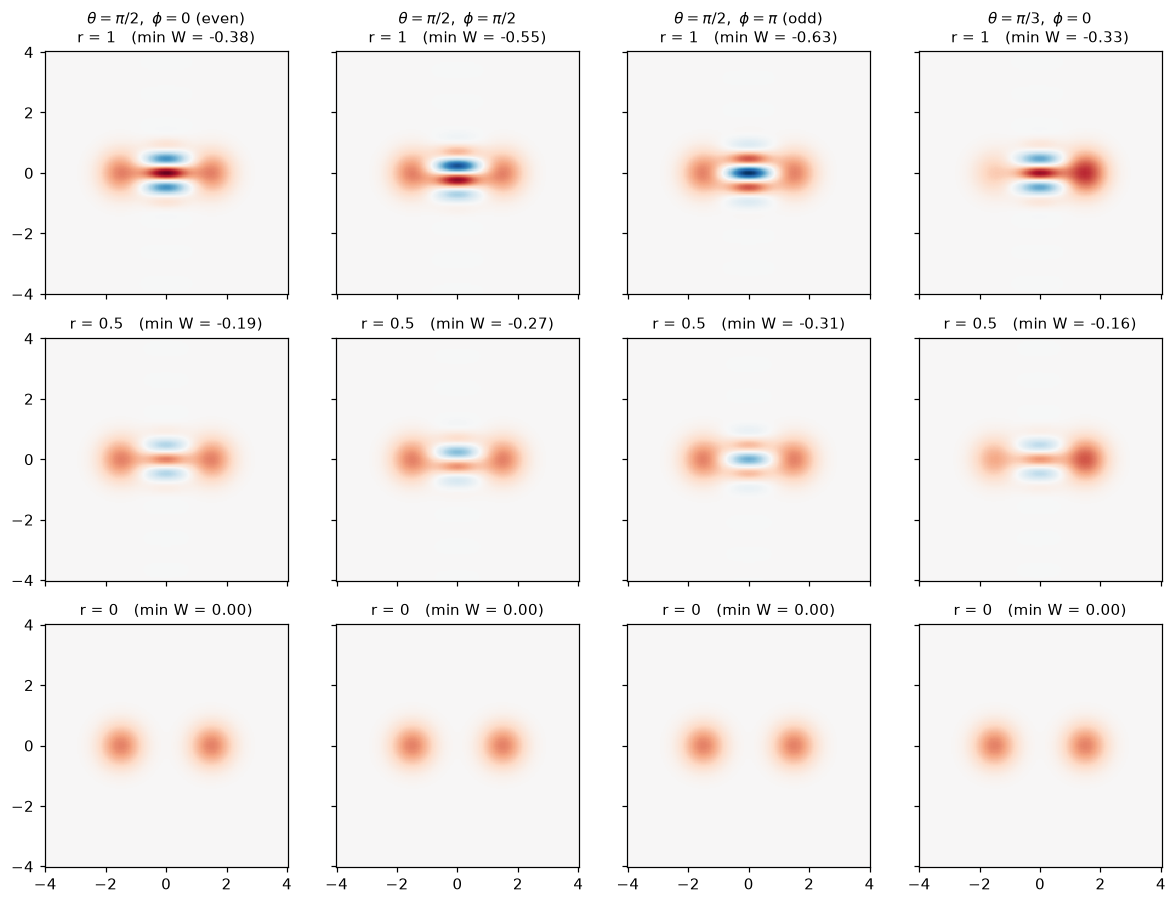

In [22]:
alpha = 1.5
rs = [1, 0.5, 0]
angles = [(np.pi/2, 0, r'$\theta=\pi/2,\ \phi=0$ (even)'), (np.pi/2, np.pi/2, r'$\theta=\pi/2,\ \phi=\pi/2$'),
          (np.pi/2, np.pi, r'$\theta=\pi/2,\ \phi=\pi$ (odd)'), (np.pi/3, 0, r'$\theta=\pi/3,\ \phi=0$')]
fig, axs = plt.subplots(len(rs), len(angles), figsize=(11, 8.3), sharex=True, sharey=True)
for i, r in enumerate(rs):
    for j, (th, ph, lab) in enumerate(angles):
        dm, PP, w = BlochToPP(r, th, ph, alpha)
        Q, P, Wg = PPToW(PP, w, 4, 4, 200)
        axs[i, j].pcolormesh(Q, P, Wg, cmap='RdBu_r', vmin=-2/np.pi, vmax=2/np.pi, rasterized=True)
        title = f'r = {r}   (min W = {Wg.min():.2f})'
        axs[i, j].set(aspect='equal', title=(lab + '\n' + title) if i == 0 else title)
plt.tight_layout(); plt.show()

### 3.3 Interactive explorer
Move the sliders to explore the Bloch-sphere family. The plot updates when a slider is released. This needs a running Jupyter kernel with `ipywidgets`. On GitHub the static figures above are shown instead.

In [23]:
try:
    from ipywidgets import interact, FloatSlider

    def explore(r=1.0, theta=np.pi/2, phi=0.0, alpha=1.5):
        dm, PP, w = BlochToPP(r, theta, phi, alpha)
        Q, P, Wg = PPToW(PP, w, 4, 4, 200)
        fig, axs = plt.subplots(1, 2, figsize=(9, 4))
        plot_pp(axs[0], PP, w, 'weighted positive-P pairs', lim=3.5)
        axs[1].pcolormesh(Q, P, Wg, cmap='RdBu_r', vmin=-2/np.pi, vmax=2/np.pi, rasterized=True)
        axs[1].set(aspect='equal', title=f'Wigner function (min W = {Wg.min():.3f})')
        plt.tight_layout(); plt.show()

    # continuous_update=False: redraw only when a slider is released, otherwise every
    # intermediate slider position queues a full redraw
    slider = lambda **kw: FloatSlider(step=0.05, continuous_update=False, **kw)
    interact(explore,
             r=slider(min=0, max=1, value=1),
             theta=slider(min=0, max=np.pi, value=np.pi/2),
             phi=slider(min=0, max=2*np.pi, value=0),
             alpha=slider(min=0.1, max=3, value=1.5))
except ImportError:
    print('ipywidgets is not installed: pip install ipywidgets to use the interactive explorer.')

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='r', max=1.0, step=0.05), Fl…

## 4. The photonic circuit

Four waveguides with nearest-neighbour couplings $J_{12}(z),J_{23}(z),J_{34}(z)$, each a sum of super-Gaussian pulses $J\,e^{-((z-z_0)/\sigma)^d}$ (`add_SuperGauss`). Waveguide 2 carries the cat, kitten or mixture. Waveguides 1, 3 and 4 carry coherent states that encode the data. The cat and the mixture are both sent through the same chip, the geometry used in the paper.

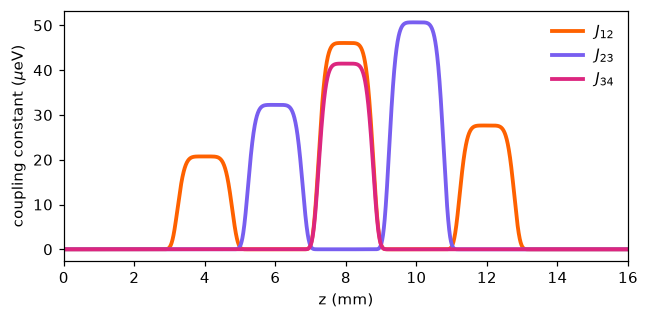

In [24]:
hbar, vg = 0.6582*1000, 0.07          # hbar in µeV·ps, group velocity in mm/ps
modes = 4
max_x = 2*(2*modes - 3) + 6           # chip length (mm)
dx = 0.005                            # integration step = spatial grid (mm)
x = np.arange(0, max_x, dx)[:-1]

# (pair j <-> j+1, centre z0 [mm], sigma [mm], d, amplitude [in units of hbar*vg])
PULSES = [(0, 4, 0.8, 6, 0.45), (1, 6, 0.8, 6, 0.7), (0, 8, 0.8, 6, 1),
          (2, 8, 0.8, 6, 0.9), (1, 10, 0.8, 6, 1.1), (0, 12, 0.8, 6, 0.6)]

J_values = np.zeros([modes-1, len(x)], dtype='complex')
for (j, z0, sigma, d, amp) in PULSES:
    J_values = add_SuperGauss(J_values, j, x, z0, sigma, d, amp)
J_values = J_values*hbar*vg
J_mat = J_matrix(J_values)

fig, ax = plt.subplots(figsize=(6, 3))
for j in range(modes-1):
    ax.plot(x, np.real(J_values[j]), lw=2.5, color=MODE_COLORS[j], label=f'$J_{{{j+1}{j+2}}}$')
ax.set(xlabel='z (mm)', ylabel=r'coupling constant ($\mu$eV)', xlim=(0, max_x))
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 5. Propagation through the chip

A data point $(x,y)\in[0,1]^2$ is encoded in the phases of the coherent inputs, exactly as in the paper:
$$\alpha_1=e^{i\phi},\quad \alpha_3=1.4\,e^{i\theta},\quad \alpha_4=i,\qquad \phi=\tfrac{\pi}{2}y,\quad \theta=\tfrac{\pi}{2}(1+x).$$
Below, a single data point is propagated through the chip, once with the even cat ($r=1$, $\alpha=1$) and once with the classical mixture ($r=0$).

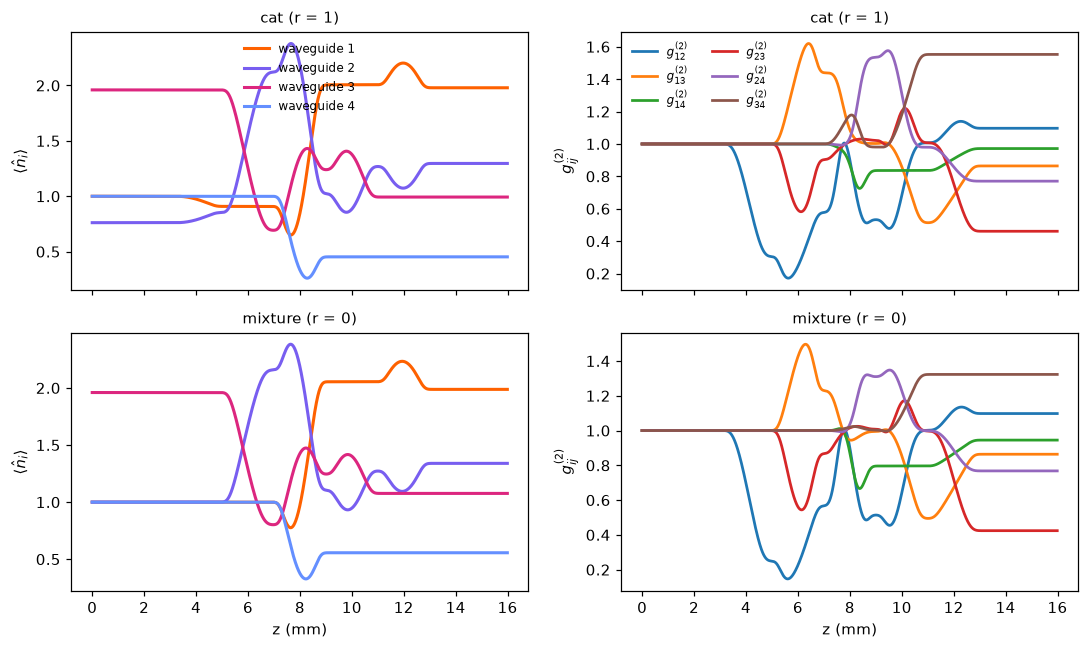

In [25]:
phase_ref = [0, 2, 3]                 # waveguides with coherent (data-encoding) inputs
W = np.ones(modes); W[phase_ref] = 0  # the cat / mixture enters waveguide 2
delta = np.zeros(modes, dtype='complex')
gamma = 0.0                           # lossless chip
Numerical = [dx, max_x]
COMBOS = list(combinations(range(modes), 2))
PAIR_LABELS = [f'$g^{{(2)}}_{{{i+1}{j+1}}}$' for i, j in COMBOS]

def encode(point):
    phi = 0.5*np.pi*point[1]
    theta = 0.5*np.pi*(1 + point[0])
    return [np.exp(1j*phi), 1.4*np.exp(1j*theta), 1j]

STATES = {'cat (r = 1)': [1, 0.5*np.pi, 0, 1], 'mixture (r = 0)': [0, 0.5*np.pi, 0, 1]}
point = (0.3, 0.7)
Physical = [hbar, vg, delta, gamma, J_mat, W, phase_ref, encode(point)]

runs = {}
for name, par in STATES.items():
    runs[name] = Positive_P_CAT(Physical, Numerical, modes, None, None,
                                viewW=True, mixed=True, mixed_par=par)

fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for row, (name, (z, N, G, Q, P, wigs, traj)) in zip(axs, runs.items()):
    for i in range(modes):
        row[0].plot(z, N[i], color=MODE_COLORS[i], lw=2, label=f'waveguide {i+1}')
    for c in range(len(COMBOS)):
        row[1].plot(z, G[c], lw=1.8, label=PAIR_LABELS[c])
    row[0].set(ylabel=r'$\langle \hat n_i\rangle$', title=name)
    row[1].set(ylabel=r'$g^{(2)}_{ij}$', title=name)
axs[0, 0].legend(frameon=False, fontsize=8); axs[0, 1].legend(frameon=False, fontsize=8, ncol=2)
for ax in axs[1]: ax.set_xlabel('z (mm)')
plt.tight_layout(); plt.show()

Single-mode Wigner functions of every waveguide at the input ($z=0$) and output of the chip. For a linear chip the reduced state of waveguide $m$ follows from the pairs restricted to that waveguide, with the same weights.

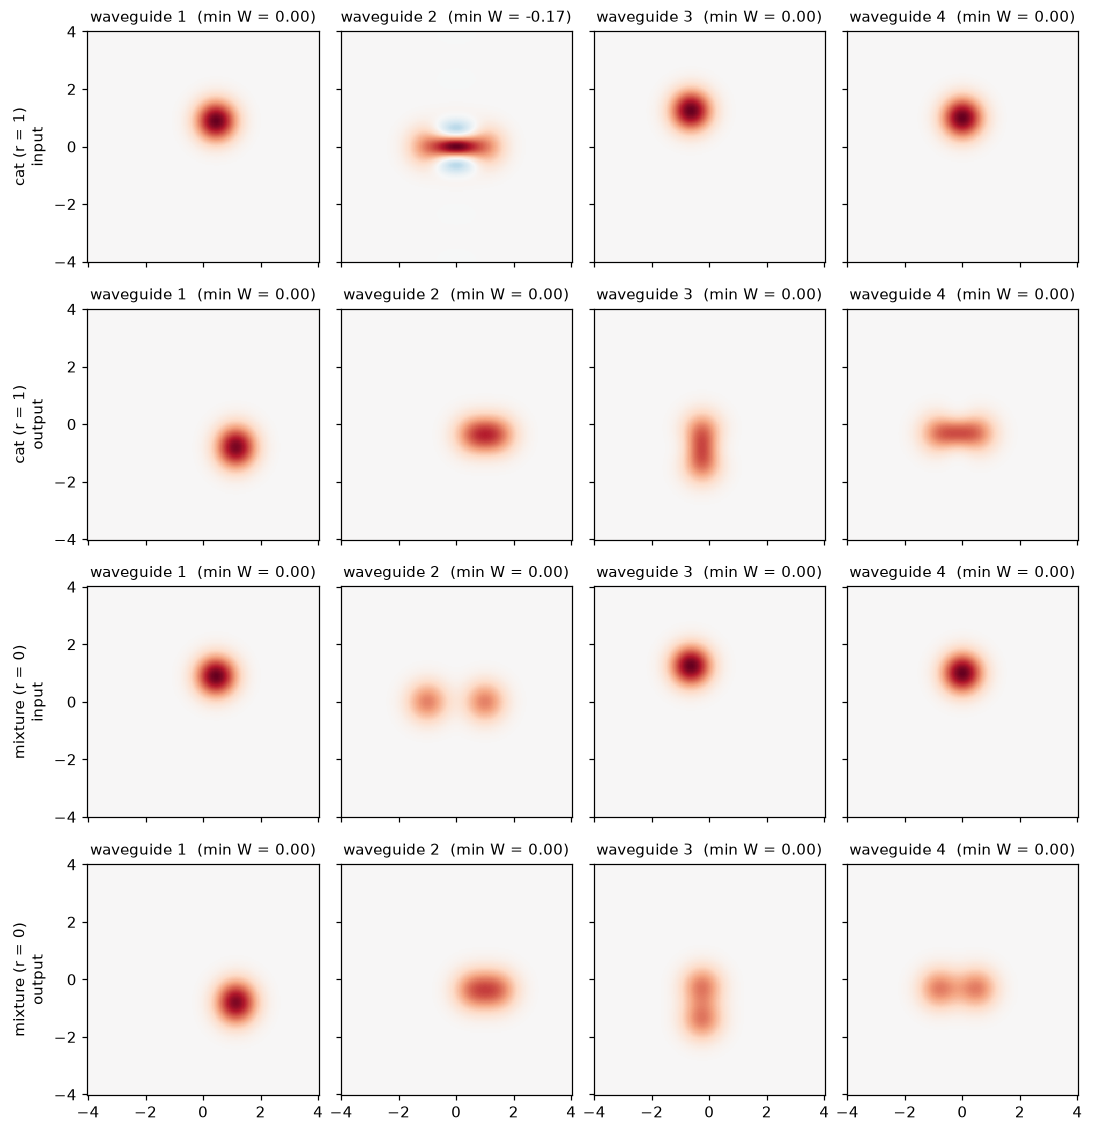

In [26]:
fig, axs = plt.subplots(4, modes, figsize=(10, 10.4), sharex=True, sharey=True)
rows = []
for name, par in STATES.items():
    weights = BlochToPP(*par)[2]
    z, N, G, Q, P, wigs, traj = runs[name]
    rows.append((f'{name}\ninput', [PPToW(traj[0, m], weights, 4, 4, 200)[2] for m in range(modes)]))
    rows.append((f'{name}\noutput', [wigs[m][0] for m in range(modes)]))
for ax_row, (lab, Ws) in zip(axs, rows):
    for m, (ax, Wg) in enumerate(zip(ax_row, Ws)):
        ax.pcolormesh(Q, P, Wg, cmap='RdBu_r', vmin=-2/np.pi, vmax=2/np.pi, rasterized=True)
        ax.set(aspect='equal', title=f'waveguide {m+1}  (min W = {Wg.min():.2f})')
    ax_row[0].set_ylabel(lab)
plt.tight_layout(); plt.show()

## 6. Reservoir computing on the two-spirals task

For each data point the chip output gives the features $\langle\hat n_i\rangle$ (4 values) and $g^{(2)}_{ij}$ (6 values). A logistic regression is trained on them. As in the paper, the accuracy is averaged over repeated random 75/25 train/test splits of 200 points per class. To keep the run time short, the data set here has 200 points per class; set `samples = 400` to use the paper's data-set size. The indices are drawn **without replacement**, so a point is never in both the training and test sets.

The comparison covers cat vs. classical mixture in the same chip, and $\langle\hat n\rangle$ vs. $g^{(2)}$ features.

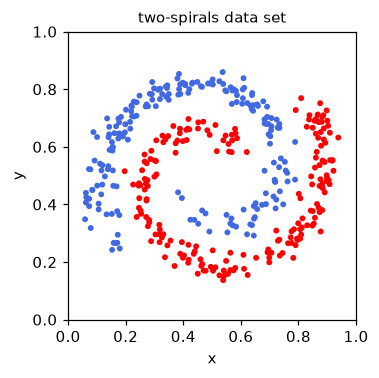

In [10]:
samples = 200                         # points per class (the paper uses 400)
m_tr, lb = Spirals(samples, seeds=[111, 123, 125, 33667])
m_tr = np.array(m_tr)

cmap_cls = mcolors.ListedColormap(['red', 'royalblue'])
fig, ax = plt.subplots(figsize=(3.4, 3.4))
ax.scatter(m_tr[:, 0], m_tr[:, 1], c=lb, cmap=cmap_cls, s=8)
ax.set(xlabel='x', ylabel='y', xlim=(0, 1), ylim=(0, 1), aspect='equal', title='two-spirals data set')
plt.show()

def chip_features(J_mat, mixed_par, points, detector_noise=False, bgr=None):
    N_out = np.zeros([len(points), modes]); G_out = np.zeros([len(points), len(COMBOS)])
    for s, pt in enumerate(points):
        Physical = [hbar, vg, delta, gamma, J_mat, W, phase_ref, encode(pt)]
        N_out[s], G_out[s] = run_CAT(None, None, Physical, Numerical, modes, mixed=True, mixed_par=mixed_par,
                                     detector_noise=detector_noise, bgr=bgr)
    return N_out, G_out

def evaluate(F, lb, reps=300, seed=0):
    rng = np.random.default_rng(seed)
    F0, F1 = F[lb == 0], F[lb == 1]
    acc = []
    for _ in range(reps):
        idx = rng.permutation(len(F0))[:200]          # 200 distinct points per class
        tr0, te0 = train_test_split(F0[idx], test_size=0.25, random_state=int(rng.integers(10**9)))
        tr1, te1 = train_test_split(F1[idx], test_size=0.25, random_state=int(rng.integers(10**9)))
        Xtr, Xte = np.vstack([tr0, tr1]), np.vstack([te0, te1])
        ytr, yte = np.r_[np.zeros(len(tr0)), np.ones(len(tr1))], np.r_[np.zeros(len(te0)), np.ones(len(te1))]
        scaler = StandardScaler().fit(Xtr)
        clf = LogisticRegression(max_iter=10000, C=100000).fit(scaler.transform(Xtr), ytr)
        acc.append(accuracy_score(yte, clf.predict(scaler.transform(Xte))))
    return np.mean(acc), np.std(acc)

In [11]:
FEATURES = {sname: chip_features(J_mat, par, m_tr) for sname, par in STATES.items()}

print(f'{"state":>16s} {"<n_i> features":>18s} {"g2_ij features":>18s}')
for sname, (N_f, G_f) in FEATURES.items():
    (aN, sN), (aG, sG) = evaluate(N_f, lb), evaluate(G_f, lb)
    print(f'{sname:>16s} {100*aN:10.1f} ± {100*sN:4.1f} % {100*aG:10.1f} ± {100*sG:4.1f} %')

           state     <n_i> features     g2_ij features


     cat (r = 1)       70.3 ±  3.9 %       96.9 ±  1.6 %


 mixture (r = 0)       70.3 ±  3.9 %       81.0 ±  3.3 %


**What to notice**
* With $\langle\hat n_i\rangle$ features the accuracy is the same for the cat and the mixture. $\langle\hat n_i\rangle$ is linear in $\hat\rho$, and the coherence pairs only shift it by a data-independent constant.
* With $g^{(2)}_{ij}$ features the accuracy rises sharply, for both states. The gain comes from measuring correlations, which are nonlinear in the encoded phases.

**Decision boundaries** for the $g^{(2)}$ features, with the classifier trained on the full data set and evaluated on a grid of input points.

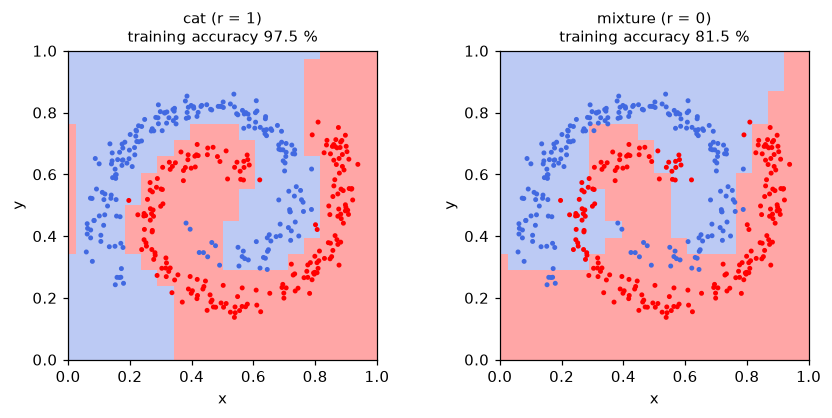

In [12]:
n_grid = 20
gx, gy = np.meshgrid(np.linspace(0, 1, n_grid), np.linspace(0, 1, n_grid))
grid_points = np.c_[gx.ravel(), gy.ravel()]

fig, axs = plt.subplots(1, len(STATES), figsize=(8, 3.8))
for ax, sname in zip(axs, STATES):
    _, G_f = FEATURES[sname]
    scaler = StandardScaler().fit(G_f)
    clf = LogisticRegression(max_iter=10000, C=100000).fit(scaler.transform(G_f), lb)
    _, G_grid = chip_features(J_mat, STATES[sname], grid_points)
    pred = clf.predict(scaler.transform(G_grid)).reshape(n_grid, n_grid)
    ax.pcolormesh(gx, gy, pred, cmap=cmap_cls, alpha=0.35, rasterized=True)
    ax.scatter(m_tr[:, 0], m_tr[:, 1], c=lb, cmap=cmap_cls, s=5)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xlabel='x', ylabel='y',
           title=f'{sname}\ntraining accuracy {100*clf.score(scaler.transform(G_f), lb):.1f} %')
plt.tight_layout(); plt.show()

**Detector background** (cat state). `detector_noise=True` adds an uncorrelated background of mean `bgr` counts to every detector. This pulls all $g^{(2)}_{ij}$ towards 1. The model only shifts the mean values (it has no shot noise), so it is a deterministic transformation of the features that mixes $\langle\hat n_i\rangle$ into $g^{(2)}_{ij}$. That is why the accuracy does not have to decrease monotonically with background.

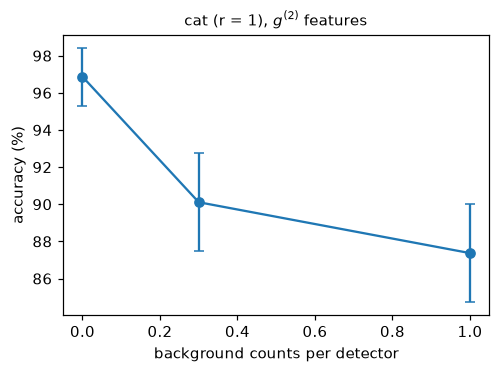

In [13]:
bgrs = [0, 0.3, 1.0]
accs = [evaluate(chip_features(J_mat, STATES['cat (r = 1)'], m_tr, detector_noise=True, bgr=b)[1], lb, reps=100)
        for b in bgrs]
fig, ax = plt.subplots(figsize=(5, 3.3))
ax.errorbar(bgrs, [100*a for a, s in accs], [100*s for a, s in accs], marker='o', capsize=3)
ax.set(xlabel='background counts per detector', ylabel='accuracy (%)', title=r'cat (r = 1), $g^{(2)}$ features')
plt.show()

## 7. Benchmark against exact Hilbert-space simulations (QuTiP)

`master` simulates the same chip in a truncated Fock space, with the same Hamiltonian, units and input state. The positive-P result has no cutoff, so the exact result should converge to it as the Fock cutoff `Ncut` grows (the Hilbert-space dimension is `Ncut**4`).

cat (r = 1)      Ncut =  6: max |Δn| = 2.0e-01, max |Δg2| = 3.3e-01


cat (r = 1)      Ncut = 12: max |Δn| = 1.3e-03, max |Δg2| = 5.1e-03


mixture (r = 0)  Ncut =  6: max |Δn| = 2.2e-01, max |Δg2| = 2.9e-01


mixture (r = 0)  Ncut = 12: max |Δn| = 1.5e-03, max |Δg2| = 4.4e-03


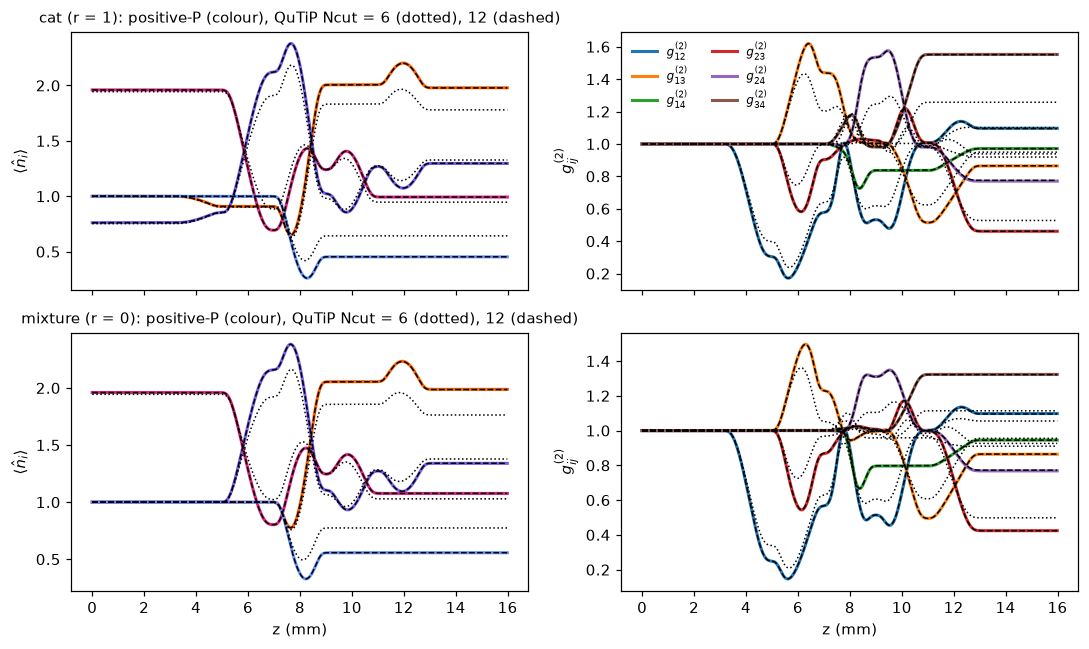

In [14]:
Physical = [hbar, vg, delta, gamma, J_mat, W, phase_ref, encode(point)]
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for row, (sname, par) in zip(axs, STATES.items()):
    z, N, G = Positive_P_CAT(Physical, Numerical, modes, None, None, mixed=True, mixed_par=par)
    for i in range(modes): row[0].plot(z, N[i], color=MODE_COLORS[i], lw=2)
    for c in range(len(COMBOS)): row[1].plot(z, G[c], lw=2, color=f'C{c}', label=PAIR_LABELS[c])
    for Ncut, ls in [(6, ':'), (12, '--')]:
        zq, nq, gq = master(modes, Ncut, hbar, vg, gamma, delta, J_values, x, par, phase_ref,
                            encode(point), cat_mode=1)
        for i in range(modes): row[0].plot(zq, nq[i], 'k', ls=ls, lw=1)
        for c in range(len(COMBOS)): row[1].plot(zq, gq[c], 'k', ls=ls, lw=1)
        print(f'{sname:16s} Ncut = {Ncut:2d}: max |Δn| = {np.abs(nq[:, -1] - N[:, -1]).max():.1e}, '
              f'max |Δg2| = {np.abs(gq[:, -1] - G[:, -1]).max():.1e}')
    row[0].set(ylabel=r'$\langle\hat n_i\rangle$', title=f'{sname}: positive-P (colour), QuTiP Ncut = 6 (dotted), 12 (dashed)')
    row[1].set(ylabel=r'$g^{(2)}_{ij}$')
axs[0, 1].legend(frameon=False, fontsize=8, ncol=2)
for ax in axs[1]: ax.set_xlabel('z (mm)')
plt.tight_layout(); plt.show()